Импорты и загрузка данных:

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, classification_report, 
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# Загрузка данных Iris
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Размер train:", X_train.shape, "Размер test:", X_test.shape)

Размер train: (120, 4) Размер test: (30, 4)


Настройка MLflow:

2026/11/16 14:40:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 14:40:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.82      0.90      0.86        10
           2       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

🏃 View run iris_run_1 at: http://127.0.0.1:5000/#/experiments/1/runs/cca34522d0484d8c924f2aa100c95abc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


<Figure size 600x400 with 0 Axes>

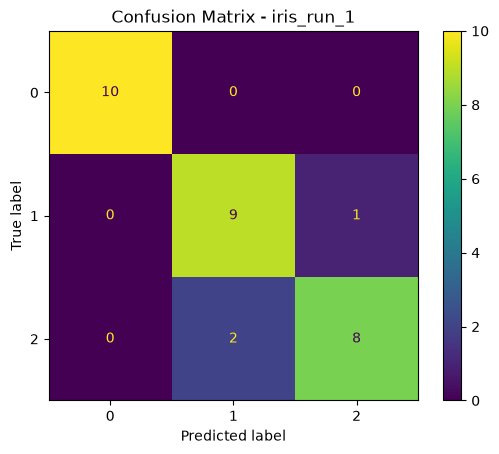

In [4]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("DEMO_Iris_Classification_Metrics")

with mlflow.start_run(run_name="iris_run_1"):
    # Обучение модели
    model = RandomForestClassifier(n_estimators=5, max_depth=2, random_state=42)
    model.fit(X_train, y_train)
    
    # Предсказания
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)
    
    mlflow.log_params({"n_estimators": 5, "max_depth": 2})
    
    # Подсчет и логирование метрик
    scores = {
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision_score(y_test, pred, average="macro"),
        "recall_macro": recall_score(y_test, pred, average="macro"),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "f1_weighted": f1_score(y_test, pred, average="weighted"),
        "roc_auc_ovr_weighted": roc_auc_score(y_test, prob, multi_class="ovr", average="weighted")
    }
    mlflow.log_metrics(scores)
    
    # Сохранение модели
    mlflow.sklearn.log_model(
        model, 
        "iris_classifier", 
        serialization_format="cloudpickle"
    )
    
    # Построение и сохранение матрицы ошибок как артефакта
    plt.figure(figsize=(6, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title("Confusion Matrix - iris_run_1")
    plt.savefig("confusion_matrix.png")
    mlflow.log_artifact("confusion_matrix.png")
    
    print(classification_report(y_test, pred))

Цикл по трем вариантам гиперпараметров:

In [5]:
variants = [
    (10, 2),
    (30, 3),
    (80, None)
]

for n_trees, depth in variants:
    run_name = f"iris_run_trees{n_trees}_depth{depth}"
    
    with mlflow.start_run(run_name=run_name):
        # Обучение
        model = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, random_state=42)
        model.fit(X_train, y_train)
        
        # Предсказания
        pred = model.predict(X_test)
        
        # Логирование параметров
        mlflow.log_params({"n_estimators": n_trees, "max_depth": depth})
        
        # Логирование метрик
        scores = {
            "accuracy": accuracy_score(y_test, pred),
            "precision_macro": precision_score(y_test, pred, average="macro"),
            "recall_macro": recall_score(y_test, pred, average="macro"),
            "f1_macro": f1_score(y_test, pred, average="macro"),
            "f1_weighted": f1_score(y_test, pred, average="weighted")
        }
        mlflow.log_metrics(scores)
        
        # Сохранение модели
        mlflow.sklearn.log_model(
            model, 
            "iris_classifier", 
            serialization_format="cloudpickle"
        )
        
        print(f"Завершен запуск: {run_name}, F1-macro: {scores['f1_macro']:.4f}")

2026/11/16 14:59:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 14:59:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 14:59:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Завершен запуск: iris_run_trees10_depth2, F1-macro: 0.9333
🏃 View run iris_run_trees10_depth2 at: http://127.0.0.1:5000/#/experiments/1/runs/3d7264445fa4484fb757786e46576ed7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/16 14:59:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 14:59:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Завершен запуск: iris_run_trees30_depth3, F1-macro: 0.9333
🏃 View run iris_run_trees30_depth3 at: http://127.0.0.1:5000/#/experiments/1/runs/861c264f6628464ab22105e567d9eb3d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/16 14:59:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Завершен запуск: iris_run_trees80_depthNone, F1-macro: 0.9333
🏃 View run iris_run_trees80_depthNone at: http://127.0.0.1:5000/#/experiments/1/runs/17e77cea5c024af7a4b998b59d06d4f1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Т.к. три модели дали одинаковые результаты, выберем, с точки зрения параметров, среднюю из них. Это - (вариант 2) 30 деревьев, глубина 3.
Загружаем модель и тестируем на одной строке:

In [6]:
# URI ИЗ ИНТЕРФЕЙСА MLFLOW
best_model_uri = "runs:/861c264f6628464ab22105e567d9eb3d/iris_classifier"

# Загрузка модели
loaded_model = mlflow.sklearn.load_model(best_model_uri)

# Тестирование на одной строке данных
new_data = iris.data.iloc[[0]]
class_id = int(loaded_model.predict(new_data)[0])
print("Предсказанный класс:", iris.target_names[class_id])

Предсказанный класс: setosa


Сохранение файла result.txt

In [7]:
best_run_name = "iris_run_trees30_depth3" 
best_params = "n_estimators=30, max_depth=3"
best_acc = 0.9333

# Создаем отдельный запуск для артефакта
with mlflow.start_run(run_name="Best_Model_Summary"):
    with open("result.txt", "w", encoding="utf-8") as f:
        f.write(f"Название запуска: {best_run_name}\n")
        f.write(f"Параметры: {best_params}\n")
        f.write(f"Accuracy: {best_acc}\n")
        
    # Логируем его в MLflow
    mlflow.log_artifact("result.txt")
    print("Файл сохранён")

Файл сохранён
🏃 View run Best_Model_Summary at: http://127.0.0.1:5000/#/experiments/1/runs/61ee38f7d6f9437db3983c94da1defd5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Индивидуальное задание с датасетом(Вариант 4):

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import mlflow
import mlflow.sklearn

# 1. Загрузка данных
df = pd.read_csv('transport_choice.csv')

# 2. Проверка данных
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
print("\nПропуски:")
print(df.isnull().sum().sum())
print("\nТипы столбцов:")
print(df.dtypes.value_counts())
print("\nКлассы в target:")
print(df['target'].value_counts())

# 3. Подготовка данных
# X - все признаки (все столбцы кроме target)
X_custom = df.drop('target', axis=1)
# y - целевая переменная
y_custom = df['target']

# Разделение на train/test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_custom, y_custom, test_size=0.2, random_state=42, stratify=y_custom
)

# 4. Обучение и логирование в MLflow
mlflow.set_experiment("Custom_CSV_Transport_Experiment")

with mlflow.start_run(run_name="transport_rf_baseline"):
    # Инициализируем и обучаем модель
    model_c = RandomForestClassifier(random_state=42)
    model_c.fit(X_train_c, y_train_c)
    
    # Делаем предсказания
    pred_c = model_c.predict(X_test_c)
    
    # Считаем метрики
    acc_c = accuracy_score(y_test_c, pred_c)
    f1_macro_c = f1_score(y_test_c, pred_c, average="macro")
    
    # Логируем параметры и метрики
    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_metric("accuracy", acc_c)
    mlflow.log_metric("f1_macro", f1_macro_c)
    
    # Сохраняем модель
    mlflow.sklearn.log_model(
        model_c, 
        "transport_model", 
        serialization_format="cloudpickle"
    )
    
    print(f"\nРЕЗУЛЬТАТЫ:")
    print(f"Accuracy на тесте: {acc_c:.4f}")
    print(f"F1-macro на тесте: {f1_macro_c:.4f}")
    print("Модель сохранена")

2026/11/16 15:24:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Количество строк: 210
Количество столбцов: 19

Пропуски:
0

Типы столбцов:
float64    18
str         1
Name: count, dtype: int64

Классы в target:
target
train    63
car      59
air      58
bus      30
Name: count, dtype: int64


2026/11/16 15:24:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



РЕЗУЛЬТАТЫ:
Accuracy на тесте: 1.0000
F1-macro на тесте: 1.0000
Модель сохранена
🏃 View run transport_rf_baseline at: http://127.0.0.1:5000/#/experiments/2/runs/9cb6b61a1cd140b6b5ab5c6c791201d3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
